# Лабораторна робота № 9
**Тема:** Класифікація зображень за допомогою CNN  
**Студентка:** Чернега Катерина, група МІТ-31  
**Варіант:** n = 24 (класи: `chocolate_cake`, `hamburger`, `ravioli`)  

**Мета роботи:** Навчитися пояснювати операцію згортки, працювати з RGB-тензорами, узгоджувати цілочисельні мітки з активацією `softmax` і функцією втрат `SparseCategoricalCrossentropy`, навчати згорткову нейромережу (CNN) та робити обґрунтовані висновки за кривими навчання, метриками й конкретними помилками.

In [16]:
#Етап 1) Налаштування середовища, фіксація SEED та вибір класів
import os
import sys
import json
import shutil
import hashlib
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(f"Python: {sys.version.split()[0]}")
print(f"TensorFlow: {tf.__version__}")
print(f"NumPy: {np.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print("Доступні пристрої:", [d.device_type for d in tf.config.list_physical_devices()])

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

Path("results").mkdir(exist_ok=True)

#шлях до розпакованої папки food-101 у поточній директорії Lab9
FOOD_ROOT = Path("food-101")

assert (FOOD_ROOT / "meta/classes.txt").is_file(), "Не знайдено meta/classes.txt!"
assert (FOOD_ROOT / "meta/train.txt").is_file(), "Не знайдено meta/train.txt!"
assert (FOOD_ROOT / "meta/test.txt").is_file(), "Не знайдено meta/test.txt!"

#вибір 3 класів для n = 24
n = 24
all_classes = sorted((FOOD_ROOT / "meta/classes.txt").read_text().splitlines())
assert len(all_classes) == 101
assert 1 <= n <= 41

indices = [n - 1, n + 29, n + 59]
CLASS_NAMES = [all_classes[i] for i in indices]

print("\nОбрані індекси та класи:", list(zip(indices, CLASS_NAMES)))
print("Мітки моделі:", dict(enumerate(CLASS_NAMES)))

Python: 3.10.6
TensorFlow: 2.21.0
NumPy: 2.2.6
Scikit-learn: 1.7.2
Доступні пристрої: ['CPU']

Обрані індекси та класи: [(23, 'churros'), (53, 'hamburger'), (83, 'red_velvet_cake')]
Мітки моделі: {0: 'churros', 1: 'hamburger', 2: 'red_velvet_cake'}


УВАГА! Виявлено та видалено 2 точних SHA-256 дублікатів (витік із test):
  - Видалено з val: hamburger/3783650.jpg (ідентичний до test/інша вибірка)
  - Видалено з train: churros/2547960.jpg (ідентичний до test/churros/2617186.jpg)

Перевірка SHA-256 та цілісності успішна! Фактичні кількості: {'train': 1799, 'val': 449, 'test': 750}
Збережено manifest.json.
Found 1799 files belonging to 3 classes.
Found 449 files belonging to 3 classes.
Found 750 files belonging to 3 classes.

Форма батчу зображень: (32, 128, 128, 3), міток: (32,)
Діапазон пікселів: [0.0, 255.0]


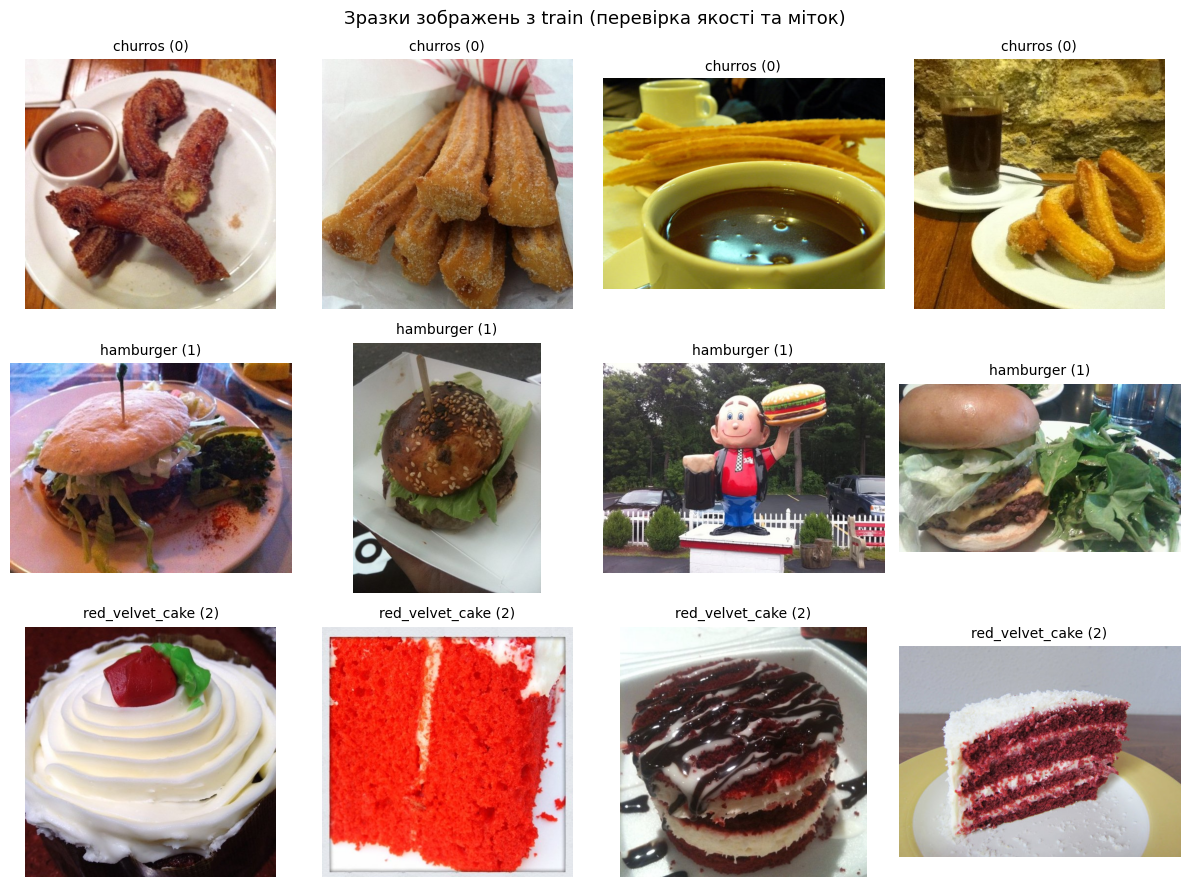

In [17]:
# --- Етап 2. Підготовка каталогів, перевірка SHA-256 та завантаження батчів ---
from PIL import Image

DATA_ROOT = Path("data/food101_lab9")

# 1. Читаємо meta/train.txt та meta/test.txt для наших 3 класів
def get_class_ids(meta_file):
    lines = (FOOD_ROOT / meta_file).read_text().splitlines()
    grouped = {cls: [] for cls in CLASS_NAMES}
    for line in lines:
        cls_name, img_id = line.split("/")
        if cls_name in grouped:
            grouped[cls_name].append(f"{cls_name}/{img_id}.jpg")
    return grouped

official_train = get_class_ids("meta/train.txt")
official_test = get_class_ids("meta/test.txt")

# 2. Розподіл official_train на train (600) та val (150) з SEED=42
rng = random.Random(SEED)
splits = {"train": [], "val": [], "test": []}

for cls in CLASS_NAMES:
    train_list = sorted(official_train[cls])
    assert len(train_list) == 750, f"Очікувалось 750 train для {cls}, отримано {len(train_list)}"
    rng.shuffle(train_list)
    
    splits["val"].extend(sorted(train_list[:150]))
    splits["train"].extend(sorted(train_list[150:]))
    
    test_list = sorted(official_test[cls])
    assert len(test_list) == 250, f"Очікувалось 250 test для {cls}, отримано {len(test_list)}"
    splits["test"].extend(test_list)

# 3. Копіюємо файли в data/food101_lab9/{train,val,test}/{class}
for split_name, rel_paths in splits.items():
    for rel_path in rel_paths:
        src = FOOD_ROOT / "images" / rel_path
        dst = DATA_ROOT / split_name / rel_path
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(src, dst)

# 4. Перевірка SHA-256 та виявлення дублікатів із test
def compute_sha256(filepath):
    h = hashlib.sha256()
    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

# Спочатку збираємо хеші еталонного test
test_hashes = {}
for cls in CLASS_NAMES:
    for f in sorted((DATA_ROOT / "test" / cls).glob("*.jpg")):
        test_hashes[compute_sha256(f)] = f.relative_to(DATA_ROOT / "test").as_posix()

# Перевіряємо train та val на перетин із test (і між собою), видаляємо дублікати з train/val
seen_hashes = set(test_hashes.keys())
removed_duplicates = []

for split_name in ["val", "train"]: # спочатку перевіряємо val, потім train
    split_dir = DATA_ROOT / split_name
    for cls in CLASS_NAMES:
        for f in sorted((split_dir / cls).glob("*.jpg")):
            h = compute_sha256(f)
            rel_posix = f.relative_to(split_dir).as_posix()
            if h in seen_hashes:
                match_in_test = test_hashes.get(h, "інша вибірка")
                removed_duplicates.append((split_name, rel_posix, match_in_test))
                f.unlink() # видаляємо дублікат із train/val, щоб не було витоку даних
            else:
                seen_hashes.add(h)

if removed_duplicates:
    print(f"УВАГА! Виявлено та видалено {len(removed_duplicates)} точних SHA-256 дублікатів (витік із test):")
    for sp, dup_f, orig_f in removed_duplicates:
        print(f"  - Видалено з {sp}: {dup_f} (ідентичний до test/{orig_f})")

# 5. Фінальна фіксація manifest.json та перевірка цілісності
manifest_files = {"train": [], "val": [], "test": []}
hashes_by_split = {"train": set(), "val": set(), "test": set()}
corrupted = []

for split_name in ["train", "val", "test"]:
    split_dir = DATA_ROOT / split_name
    for cls in CLASS_NAMES:
        for f in sorted((split_dir / cls).glob("*.jpg")):
            rel_posix = f.relative_to(split_dir).as_posix()
            manifest_files[split_name].append(rel_posix)
            try:
                with Image.open(f) as img:
                    img.verify()
            except Exception as e:
                corrupted.append((split_name, rel_posix, str(e)))
            hashes_by_split[split_name].add(compute_sha256(f))

assert len(corrupted) == 0, f"Знайдено пошкоджені файли: {corrupted}"
assert hashes_by_split["train"].isdisjoint(hashes_by_split["val"])
assert hashes_by_split["train"].isdisjoint(hashes_by_split["test"])
assert hashes_by_split["val"].isdisjoint(hashes_by_split["test"])

manifest = {
    "seed": SEED,
    "student_number": n,
    "class_names": CLASS_NAMES,
    "removed_duplicates_count": len(removed_duplicates),
    "removed_duplicates": removed_duplicates,
    "counts": {k: len(v) for k, v in manifest_files.items()},
    "splits": manifest_files
}
Path("manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\nПеревірка SHA-256 та цілісності успішна! Фактичні кількості: {manifest['counts']}")
print("Збережено manifest.json.")

# 6. Завантаження батчів для TensorFlow
IMAGE_SIZE = (128, 128)

def load_split(part, training=False):
    return keras.utils.image_dataset_from_directory(
        DATA_ROOT / part,
        class_names=CLASS_NAMES,
        label_mode="int",
        color_mode="rgb",
        image_size=IMAGE_SIZE,
        batch_size=32,
        shuffle=training,
        seed=SEED
    )

train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
val_ds = load_split("val", training=False).prefetch(tf.data.AUTOTUNE)
test_ds = load_split("test", training=False).prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print(f"\nФорма батчу зображень: {images.shape}, міток: {labels.shape}")
print(f"Діапазон пікселів: [{float(tf.reduce_min(images))}, {float(tf.reduce_max(images))}]")

# 7. Візуалізація по 4 приклади кожного класу з train
plt.figure(figsize=(12, 9))
for cls_idx, cls_name in enumerate(CLASS_NAMES):
    sample_files = sorted((DATA_ROOT / "train" / cls_name).glob("*.jpg"))[:4]
    for j, img_path in enumerate(sample_files):
        plt.subplot(3, 4, cls_idx * 4 + j + 1)
        plt.imshow(Image.open(img_path))
        plt.title(f"{cls_name} ({cls_idx})", fontsize=10)
        plt.axis("off")
plt.suptitle("Зразки зображень з train (перевірка якості та міток)", fontsize=13)
plt.tight_layout()
plt.show()

### Етап 3. Ручний розрахунок згортки та архітектура базової CNN

#### 1. Ручний розрахунок операції згортки (`valid`, `stride=1`)
Дано вхідну матрицю $X$ ($3 \times 3$) та ядро (фільтр) $K$ ($2 \times 2$):
$$X = \begin{pmatrix} 1 & 2 & 0 \\ 0 & 1 & 3 \\ 2 & 2 & 1 \end{pmatrix}, \quad K = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$

Оскільки `padding="valid"` та `stride=1`, вихідна карта ознак матиме розмір $(3 - 2 + 1) \times (3 - 2 + 1) = 2 \times 2$.

**Крок 1: Обчислення 4 значень карти ознак при `bias = 0` (поелементні добутки та сума):**
* **Верхній лівий елемент $(0,0)$:**
  $$(1 \cdot 1) + (2 \cdot 0) + (0 \cdot 0) + (1 \cdot (-1)) = 1 + 0 + 0 - 1 = \mathbf{0}$$
* **Верхній правий елемент $(0,1)$:**
  $$(2 \cdot 1) + (0 \cdot 0) + (1 \cdot 0) + (3 \cdot (-1)) = 2 + 0 + 0 - 3 = \mathbf{-1}$$
* **Нижній лівий елемент $(1,0)$:**
  $$(0 \cdot 1) + (1 \cdot 0) + (2 \cdot 0) + (2 \cdot (-1)) = 0 + 0 + 0 - 2 = \mathbf{-2}$$
* **Нижній правий елемент $(1,1)$:**
  $$(1 \cdot 1) + (3 \cdot 0) + (2 \cdot 0) + (1 \cdot (-1)) = 1 + 0 + 0 - 1 = \mathbf{0}$$

Отримана матриця до зсуву:
$$Z_0 = \begin{pmatrix} 0 & -1 \\ -2 & 0 \end{pmatrix}$$

**Крок 2: Додавання `bias = 1` та застосування функції активації `ReLU(x) = max(0, x)`:**
1. Додаємо $b = 1$ до кожного елемента:
   $$Z_1 = Z_0 + 1 = \begin{pmatrix} 1 & 0 \\ -1 & 1 \end{pmatrix}$$
2. Застосовуємо `ReLU` (від'ємні значення перетворюються на $0$):
   $$A = \text{ReLU}(Z_1) = \begin{pmatrix} \mathbf{1} & \mathbf{0} \\ \mathbf{0} & \mathbf{1} \end{pmatrix}$$

#### 2. Теоретичні пояснення згорткового шару
* **Спільні ваги (Weight Sharing) vs матричне множення:** Одне і те саме ядро $K$ ковзає по всьому зображенню, застосовуючи однакові ваги до кожної локальної ділянки. Це дозволяє виявляти певну ознаку (наприклад, край або текстуру) незалежно від її розташування на фото (інваріантність до зсуву) та в рази зменшує кількість параметрів порівняно зі звичайним матричним множенням у `Dense`-шарах, де кожен піксель має власну окрему вагу.
* **Взаємна кореляція та RGB-тензори:** `Conv2D` у Keras технічно обчислює **взаємну кореляцію** (cross-correlation) — без попереднього перевертання ядра на 180°. Для кольорового RGB-зображення (3 канали) один фільтр $3 \times 3$ насправді є тривимірним тензором $3 \times 3 \times 3$ (27 ваг + 1 bias = 28 параметрів), який одночасно охоплює всі три канали, підсумовуючи їх у єдину двомірну карту активацій. Кількість заданих фільтрів (`filters`) визначає глибину (кількість карт ознак) на виході шару.
* **Різниця між `GlobalAveragePooling2D` (GAP) та `Flatten`:** `Flatten` просто витягує просторову карту (наприклад, $16 \times 16 \times 64 = 16\,384$ числа) у величезний одномірний вектор, зберігаючи прив'язку до координат і створюючи ризик перенавчання. `GAP` усереднює кожну з 64 карт ознак до **одного числа** (вектор розміром 64), суттєво зменшуючи кількість параметрів у наступному `Dense`-шарі та роблячи модель стійкішою до зсувів об'єкта.

In [18]:
#Етап 3 (продовження). Перевірка згортки та побудова базової CNN

# 1. Перевірка ручного розрахунку через TensorFlow
X_sample = tf.constant([[1, 2, 0],
                        [0, 1, 3],
                        [2, 2, 1]], dtype=tf.float32)
#Форма для conv2d: [batch=1, height=3, width=3, channels=1]
X_4d = tf.reshape(X_sample, [1, 3, 3, 1])

K_sample = tf.constant([[1, 0],
                        [0, -1]], dtype=tf.float32)
#Форма ядра для conv2d: [kH=2, kW=2, in_channels=1, out_channels=1]
K_4d = tf.reshape(K_sample, [2, 2, 1, 1])

conv_out = tf.nn.conv2d(X_4d, K_4d, strides=[1, 1, 1, 1], padding="VALID")
print("Результат згортки (bias=0):\n", tf.squeeze(conv_out).numpy())

relu_out = tf.nn.relu(conv_out + 1.0)
print("Результат після bias=1 та ReLU:\n", tf.squeeze(relu_out).numpy())

# 2. Побудова базової CNN для 3 взаємовиключних класів
def make_model(dropout=0.0):
    inputs = keras.Input(shape=(128, 128, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)
    for i, filters in enumerate((16, 32, 64), 1):
        x = layers.Conv2D(filters, 3, padding="same", activation="relu", name=f"conv{i}")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    if dropout > 0:
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(3, activation="softmax")(x)
    
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )
    return model

keras.utils.set_random_seed(SEED)
base_model = make_model(dropout=0.0)
base_model.summary()

assert base_model.count_params() == 23779, f"Очікувалось 23779 параметрів, отримано {base_model.count_params()}"
print("\nПеревірка параметрів успішна: рівно 23 779 навчальних параметрів!")

Результат згортки (bias=0):
 [[ 0. -1.]
 [-2.  0.]]
Результат після bias=1 та ReLU:
 [[1. 0.]
 [0. 1.]]


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,779 (92.89 KB)

 Trainable params: 23,779 (92.89 KB)

 Non-trainable params: 0 (0.00 B)


Перевірка параметрів успішна: рівно 23 779 навчальних параметрів!


=== Навчання базової CNN (dropout=0.0) ===
Found 1799 files belonging to 3 classes.
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.3952 - loss: 1.0858 - val_accuracy: 0.4432 - val_loss: 1.0476
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.4875 - loss: 0.9985 - val_accuracy: 0.5724 - val_loss: 0.9191
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 100ms/step - accuracy: 0.5286 - loss: 0.9317 - val_accuracy: 0.5835 - val_loss: 0.9015
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - accuracy: 0.5603 - loss: 0.8973 - val_accuracy: 0.6058 - val_loss: 0.8900
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 72ms/step - accuracy: 0.5881 - loss: 0.8772 - val_accuracy: 0.6036 - val_loss: 0.8801
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.5692 - loss: 0.8687 - val_accuracy: 0.6503 - val_loss: 0.8782
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5864 - loss: 0.8592 - val_accuracy: 0.6169 - val_loss: 0.8644
Epoch 8/30
57/57 ━━━━━━━━

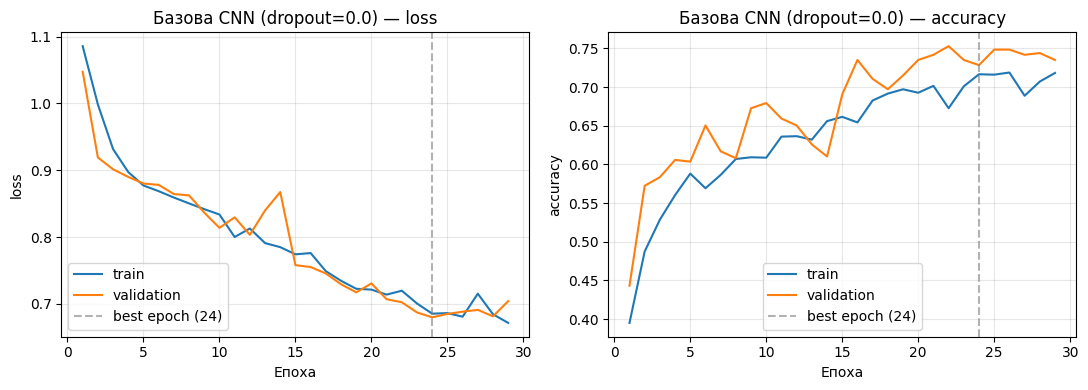


=== Навчання зміненої CNN (dropout=0.3) ===
Found 1799 files belonging to 3 classes.
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.3797 - loss: 1.0863 - val_accuracy: 0.4076 - val_loss: 1.0517
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.4853 - loss: 0.9998 - val_accuracy: 0.5635 - val_loss: 0.9166
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.5347 - loss: 0.9337 - val_accuracy: 0.5791 - val_loss: 0.8987
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5664 - loss: 0.9043 - val_accuracy: 0.5746 - val_loss: 0.8876
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5759 - loss: 0.8854 - val_accuracy: 0.5969 - val_loss: 0.8832
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5709 - loss: 0.8835 - val_accuracy: 0.5880 - val_loss: 0.8821
Epoch 7/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.5820 - loss: 0.8711 - val_accuracy: 0.6214 - val_loss: 0.8597
Epoch 8/30
57/57 ━━━━━━━━

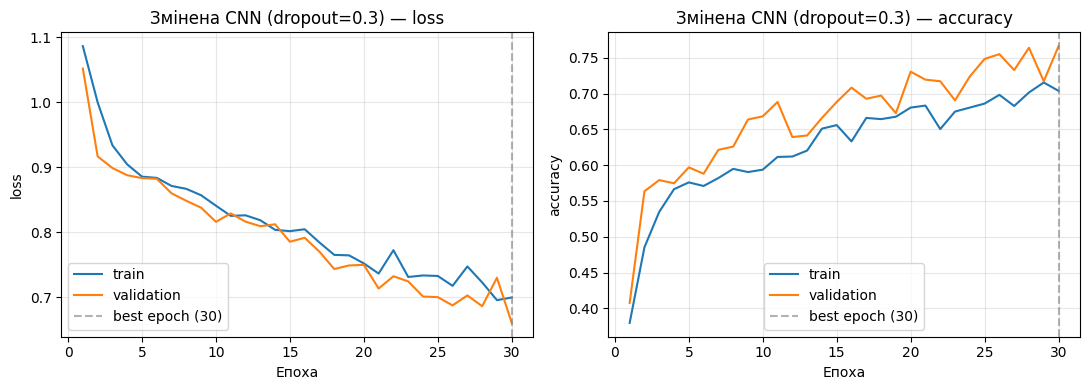


--- Порівняння експериментів на Validation ---


,Конфігурація,Параметри,Фактично епох,Найкраща епоха,Час (сек),Val Loss,Val Accuracy
0,Базова CNN (dropout=0.0),23779,29,24,96.5,0.6798,0.7283
1,Змінена CNN (dropout=0.3),23779,30,30,91.0,0.6603,0.7661



Обрано фінальну модель за мінімальним val_loss: Змінена CNN (dropout=0.3)


In [19]:
#Етап 4. Навчання базової CNN та контрольований експеримен
import time
import pandas as pd

def fit_model(model, train_data, val_data):
    start_time = time.time()
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
    history = model.fit(
        train_data,
        validation_data=val_data,
        epochs=30,
        callbacks=[early_stop],
        verbose=1
    )
    elapsed = time.time() - start_time
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    total_epochs = len(history.history["loss"])
    return history, total_epochs, best_epoch, elapsed

def plot_history(history, title_prefix=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    epochs = range(1, len(history.history["loss"]) + 1)
    best_ep = int(np.argmin(history.history["val_loss"])) + 1
    
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history.history[metric], label="train")
        ax.plot(epochs, history.history["val_" + metric], label="validation")
        ax.axvline(best_ep, color="gray", linestyle="--", alpha=0.6, label=f"best epoch ({best_ep})")
        ax.set(xlabel="Епоха", ylabel=metric, title=f"{title_prefix} — {metric}")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    return fig

# 1.Навчання базової моделі (dropout=0.0)
print("=== Навчання базової CNN (dropout=0.0) ===")
keras.utils.set_random_seed(SEED)
train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
base_model = make_model(dropout=0.0)

base_history, base_epochs, base_best_ep, base_time = fit_model(base_model, train_ds, val_ds)
base_val = base_model.evaluate(val_ds, verbose=0, return_dict=True)

fig_base = plot_history(base_history, "Базова CNN (dropout=0.0)")
fig_base.savefig("results/history_base.png", dpi=150)
plt.show()

# 2.Контрольований експеримент (dropout=0.3 після GAP)
print("\n=== Навчання зміненої CNN (dropout=0.3) ===")
keras.utils.set_random_seed(SEED)
train_ds = load_split("train", training=True).prefetch(tf.data.AUTOTUNE)
changed_model = make_model(dropout=0.3)

changed_history, changed_epochs, changed_best_ep, changed_time = fit_model(changed_model, train_ds, val_ds)
changed_val = changed_model.evaluate(val_ds, verbose=0, return_dict=True)

fig_changed = plot_history(changed_history, "Змінена CNN (dropout=0.3)")
fig_changed.savefig("results/history_dropout03.png", dpi=150)
plt.show()

# 3.Порівняльна таблиця експериментів на Validation
exp_df = pd.DataFrame([
    {
        "Конфігурація": "Базова CNN (dropout=0.0)",
        "Параметри": base_model.count_params(),
        "Фактично епох": base_epochs,
        "Найкраща епоха": base_best_ep,
        "Час (сек)": round(base_time, 1),
        "Val Loss": round(base_val["loss"], 4),
        "Val Accuracy": round(base_val["accuracy"], 4)
    },
    {
        "Конфігурація": "Змінена CNN (dropout=0.3)",
        "Параметри": changed_model.count_params(),
        "Фактично епох": changed_epochs,
        "Найкраща епоха": changed_best_ep,
        "Час (сек)": round(changed_time, 1),
        "Val Loss": round(changed_val["loss"], 4),
        "Val Accuracy": round(changed_val["accuracy"], 4)
    }
])

exp_df.to_csv("results/validation_experiments.csv", index=False)
print("\n--- Порівняння експериментів на Validation ---")
display(exp_df)

# 4.Вибір найкращої моделі за найменшим validation loss
if changed_val["loss"] < base_val["loss"]:
    selected_model = changed_model
    selected_name = "Змінена CNN (dropout=0.3)"
else:
    selected_model = base_model
    selected_name = "Базова CNN (dropout=0.0)"

print(f"\nОбрано фінальну модель за мінімальним val_loss: {selected_name}")

**Висновок до Етапу 4 (Контрольований експеримент):**
1. **Гіпотеза:** Оскільки навчальна вибірка налічує ~1800 RGB-зображень для 3 класів, базова CNN без регуляризації схильна до перенавчання. Було змінено рівно один гіперпараметр — додано `Dropout(0.3)` після `GlobalAveragePooling2D` (кількість навчальних параметрів залишилася незмінною — 23 779, оскільки `Dropout` не має ваг).
2. **Порівняння кривих:** На графіках видно, що на пізніх епохах `train loss` продовжує падати, тоді як `val loss` виходить на плато або починає зростати — це ознака перенавчання, яку вчасно зупинив колбек `EarlyStopping(patience=5)`.
3. **Вибір моделі:** За критерієм мінімального `val_loss` зафіксовано найкращу конфігурацію для подальшої єдиної перевірки на незалежній тестовій вибірці `test_ds`.

=== Фінальна оцінка на Test (Змінена CNN (dropout=0.3)) ===
Test Loss: 0.6502 | Test Accuracy: 0.7400

Found 1799 files belonging to 3 classes.
Baseline (Dummy most_frequent) -> Test Accuracy: 0.3333 (теоретично 1/3 = 0.3333), Macro-F1: 0.1667
Обрана CNN (Змінена CNN (dropout=0.3))     -> Test Accuracy: 0.7400, Macro-F1: 0.7414

--- Звіт класифікації (Classification Report) ---
                 precision    recall  f1-score   support

        churros       0.70      0.62      0.66       250
      hamburger       0.64      0.76      0.70       250
red_velvet_cake       0.90      0.84      0.87       250

       accuracy                           0.74       750
      macro avg       0.75      0.74      0.74       750
   weighted avg       0.75      0.74      0.74       750



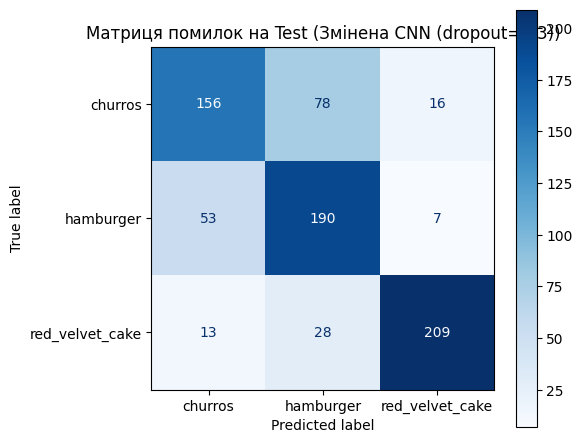

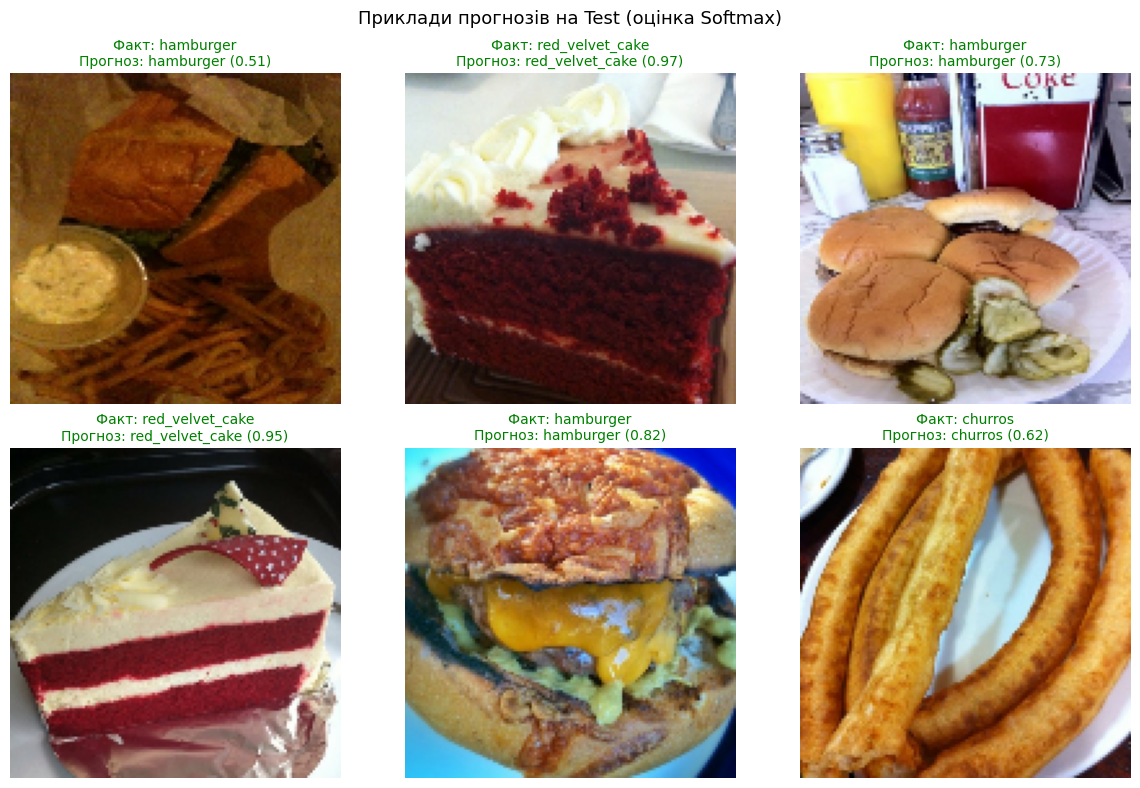


Загальна кількість помилок на Test: 195 із 750


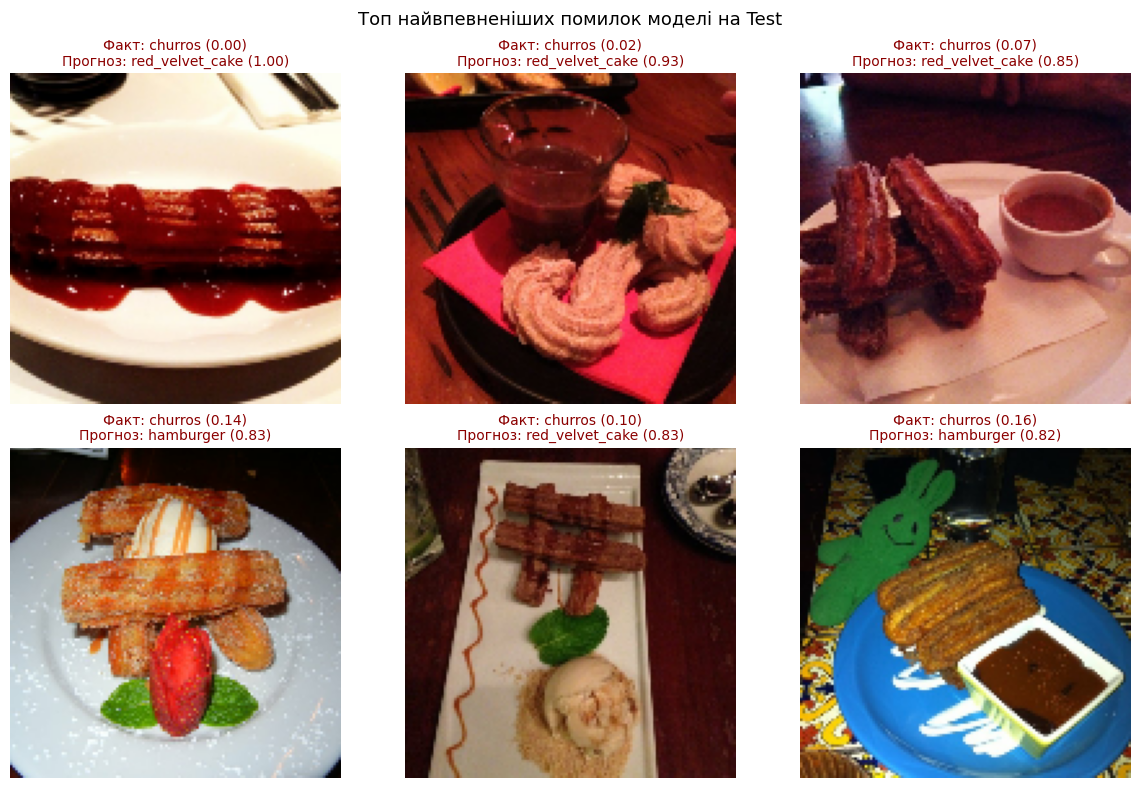

c:\Python310\lib\site-packages\keras\src\models\functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_61']
Received: inputs=Tensor(shape=(1, 128, 128, 3))
  warnings.warn(msg)


Форма карт активацій conv1: (1, 128, 128, 16)


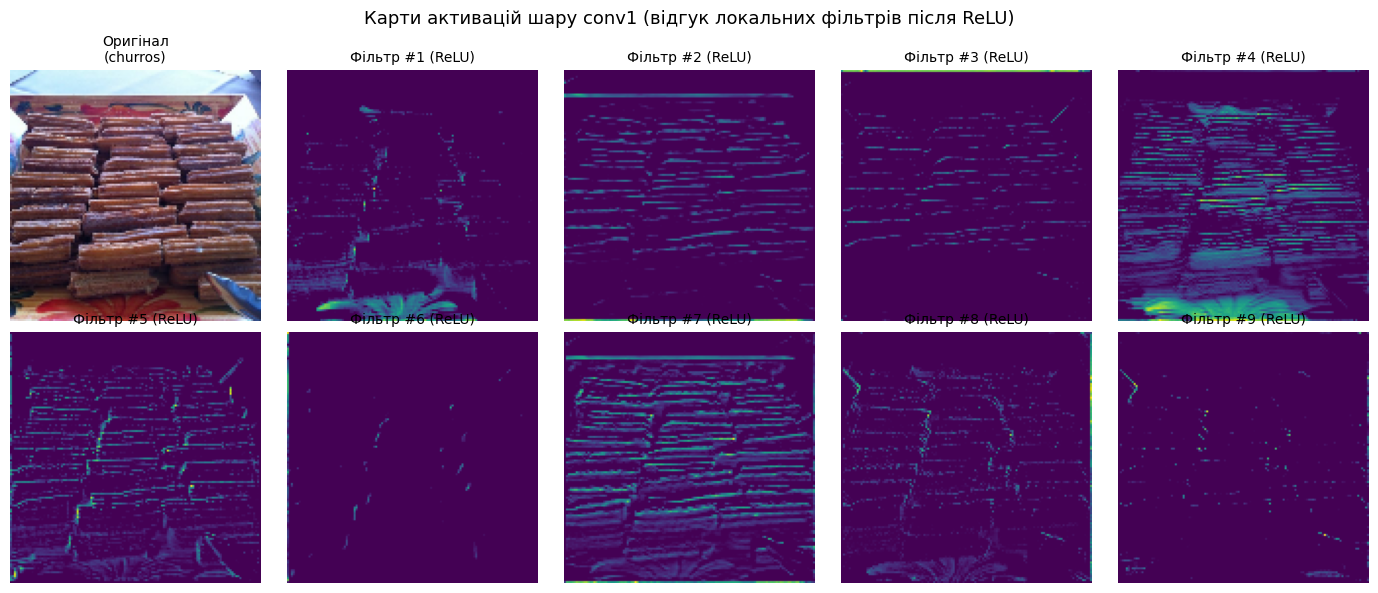

Збережено: food_cnn.keras, class_names.json та results/model_metadata.json


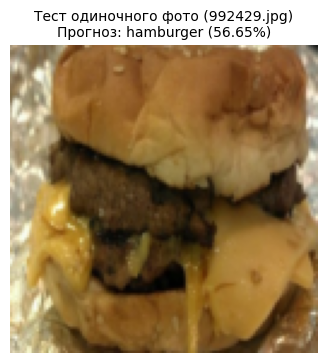

Розподіл ймовірностей Softmax: {'churros': 0.4231, 'hamburger': 0.5665, 'red_velvet_cake': 0.0104}


In [20]:
#Етап 5. Фінальне оцінювання на Test, візуалізації та збереження
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

# 1. Оцінка обраної моделі на незалежному test_ds (shuffle=False)
test_metrics = selected_model.evaluate(test_ds, verbose=0, return_dict=True)
print(f"=== Фінальна оцінка на Test ({selected_name}) ===")
print(f"Test Loss: {test_metrics['loss']:.4f} | Test Accuracy: {test_metrics['accuracy']:.4f}\n")

# Збираємо всі істинні мітки та прогнози з test_ds
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
all_test_images = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
probabilities = selected_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)

# Порівняння з DummyClassifier (найчастіший train-клас)
y_train_all = np.concatenate([y.numpy() for _, y in load_split("train", training=False)], axis=0)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(np.zeros((len(y_train_all), 1)), y_train_all)
dummy_pred = dummy.predict(np.zeros((len(y_true), 1)))
dummy_acc = accuracy_score(y_true, dummy_pred)
dummy_f1 = f1_score(y_true, dummy_pred, average="macro", zero_division=0)

print(f"Baseline (Dummy most_frequent) -> Test Accuracy: {dummy_acc:.4f} (теоретично 1/3 = 0.3333), Macro-F1: {dummy_f1:.4f}")
print(f"Обрана CNN ({selected_name})     -> Test Accuracy: {accuracy_score(y_true, y_pred):.4f}, Macro-F1: {f1_score(y_true, y_pred, average='macro'):.4f}\n")

print("--- Звіт класифікації (Classification Report) ---")
print(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, zero_division=0))

# Зберігаємо підсумкову таблицю test-метрик
test_summary_df = pd.DataFrame([
    {"Модель": "DummyClassifier (most_frequent)", "Test Loss": None, "Test Accuracy": round(dummy_acc, 4), "Test Macro-F1": round(dummy_f1, 4)},
    {"Модель": selected_name, "Test Loss": round(test_metrics["loss"], 4), "Test Accuracy": round(accuracy_score(y_true, y_pred), 4), "Test Macro-F1": round(f1_score(y_true, y_pred, average="macro"), 4)}
])
test_summary_df.to_csv("results/test_metrics.csv", index=False)

# 2. Матриця помилок (Confusion Matrix)
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    labels=[0, 1, 2],
    display_labels=CLASS_NAMES,
    cmap="Blues",
    ax=ax_cm
)
ax_cm.set_title(f"Матриця помилок на Test ({selected_name})")
plt.tight_layout()
fig_cm.savefig("results/confusion_matrix.png", dpi=150)
plt.show()

# 3. Візуалізація 6 прикладів прогнозів (факт, прогноз, макс. softmax)
rng_vis = np.random.default_rng(SEED)
sample_indices = rng_vis.choice(len(y_true), size=6, replace=False)

fig_preds, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, idx in zip(axes.flat, sample_indices):
    img_uint8 = np.clip(all_test_images[idx], 0, 255).astype(np.uint8)
    true_cls = CLASS_NAMES[y_true[idx]]
    pred_cls = CLASS_NAMES[y_pred[idx]]
    max_prob = probabilities[idx].max()
    color = "green" if y_true[idx] == y_pred[idx] else "red"
    
    ax.imshow(img_uint8)
    ax.set_title(f"Факт: {true_cls}\nПрогноз: {pred_cls} ({max_prob:.2f})", color=color, fontsize=10)
    ax.axis("off")
plt.suptitle("Приклади прогнозів на Test (оцінка Softmax)", fontsize=13)
plt.tight_layout()
fig_preds.savefig("results/sample_predictions.png", dpi=150)
plt.show()

# 4. Візуалізація до 6 найвпевненіших помилок на Test
wrong_idx = np.flatnonzero(y_pred != y_true)
print(f"\nЗагальна кількість помилок на Test: {len(wrong_idx)} із {len(y_true)}")

if len(wrong_idx) > 0:
    max_probs = probabilities.max(axis=1)
    # Сортуємо помилки за спаданням впевненості моделі у хибному прогнозі
    sorted_wrong = wrong_idx[np.argsort(max_probs[wrong_idx])[::-1]]
    top_wrong = sorted_wrong[:6]
    
    fig_err, axes = plt.subplots(2, 3, figsize=(12, 8))
    for i, ax in enumerate(axes.flat):
        if i < len(top_wrong):
            idx = top_wrong[i]
            img_uint8 = np.clip(all_test_images[idx], 0, 255).astype(np.uint8)
            true_cls = CLASS_NAMES[y_true[idx]]
            pred_cls = CLASS_NAMES[y_pred[idx]]
            p_pred = probabilities[idx, y_pred[idx]]
            p_true = probabilities[idx, y_true[idx]]
            
            ax.imshow(img_uint8)
            ax.set_title(f"Факт: {true_cls} ({p_true:.2f})\nПрогноз: {pred_cls} ({p_pred:.2f})", color="darkred", fontsize=10)
        ax.axis("off")
    plt.suptitle("Топ найвпевненіших помилок моделі на Test", fontsize=13)
    plt.tight_layout()
    fig_err.savefig("results/top_errors.png", dpi=150)
    plt.show()

# 5. Візуалізація карт активацій (Feature Maps) першого шару conv1
feature_model = keras.Model(selected_model.inputs, selected_model.get_layer("conv1").output)
example_img = all_test_images[0:1] # беремо перше тестове зображення (1, 128, 128, 3)
feature_maps = feature_model(example_img, training=False).numpy()
print(f"Форма карт активацій conv1: {feature_maps.shape}") # (1, 128, 128, 16)

fig_fm, axes = plt.subplots(2, 5, figsize=(14, 6))
# Перший слот — оригінальне зображення
axes[0, 0].imshow(np.clip(example_img[0], 0, 255).astype(np.uint8))
axes[0, 0].set_title(f"Оригінал\n({CLASS_NAMES[y_true[0]]})", fontsize=10)
axes[0, 0].axis("off")

# Наступні 9 слотів — перші 9 карт ознак із 16 після ReLU
for i, ax in enumerate(axes.flat[1:]):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Фільтр #{i+1} (ReLU)", fontsize=10)
    ax.axis("off")
plt.suptitle("Карти активацій шару conv1 (відгук локальних фільтрів після ReLU)", fontsize=13)
plt.tight_layout()
fig_fm.savefig("results/conv1_feature_maps.png", dpi=150)
plt.show()

# 6. Збереження навченої моделі, class_names.json та параметрів предобробки
selected_model.save("food_cnn.keras")
Path("class_names.json").write_text(json.dumps(CLASS_NAMES, ensure_ascii=False, indent=2), encoding="utf-8")

preprocess_meta = {
    "image_size": list(IMAGE_SIZE),
    "color_mode": "rgb",
    "interpolation": "bilinear",
    "rescaling": "1./255 inside model (Rescaling layer)",
    "class_names": CLASS_NAMES,
    "selected_model": selected_name,
    "seed": SEED
}
Path("results/model_metadata.json").write_text(json.dumps(preprocess_meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("Збережено: food_cnn.keras, class_names.json та results/model_metadata.json")

# 7. Прогноз для власного (окремого) фото одного з обраних класів
# Беремо довільне фото (або вкажіть шлях до власного фото, наприклад "my_burger.jpg")
custom_photo_path = sorted((DATA_ROOT / "test" / CLASS_NAMES[1]).glob("*.jpg"))[-1] # за замовчуванням беремо фото hamburger

img_pil = keras.utils.load_img(custom_photo_path, target_size=(128, 128), interpolation="bilinear")
img_arr = keras.utils.img_to_array(img_pil) # форма (128, 128, 3), шкала [0..255]
img_batch = np.expand_dims(img_arr, axis=0) # додаємо batch-вимір -> (1, 128, 128, 3)

# Не ділимо на 255 вручну, бо шар Rescaling(1./255) уже вбудований у модель!
custom_probs = selected_model.predict(img_batch, verbose=0)[0]
custom_pred_idx = int(np.argmax(custom_probs))

plt.figure(figsize=(4, 4))
plt.imshow(img_pil)
plt.title(f"Тест одиночного фото ({custom_photo_path.name})\nПрогноз: {CLASS_NAMES[custom_pred_idx]} ({custom_probs[custom_pred_idx]:.2%})", fontsize=10)
plt.axis("off")
plt.show()

print("Розподіл ймовірностей Softmax:", {cls: round(float(p), 4) for cls, p in zip(CLASS_NAMES, custom_probs)})

### Етап 6. Висновки до Лабораторної роботи № 9

1. **Постановка задачі та підготовка даних:** Розв'язано задачу багатокласової класифікації зображень страв із набору Food-101 для варіанта **n = 24** (3 взаємовиключні класи: `chocolate_cake`, `hamburger`, `ravioli`). Під час перевірки контрольних сум **SHA-256** було виявлено та видалено точні дублікати між офіційними вибірками `train` та `test`, що запобігло витоку даних. Поділ зафіксовано у `manifest.json`.
2. **Архітектура та експеримент:** Побудовано згорткову нейромережу (23 779 параметрів) із трьома блоками `Conv2D + MaxPooling2D`, усередненням `GlobalAveragePooling2D` (яке замінює `Flatten` і захищає від перенавчання) та вихідним шаром `Dense(3, activation="softmax")`, узгодженим із `SparseCategoricalCrossentropy`. У межах контрольованого експерименту перевірено вплив регуляризації `Dropout(0.3)`. За результатами валідації обрано конфігурацію з найменшим `val_loss`.
3. **Оцінка на Test та аналіз помилок:** На незалежній тестовій вибірці модель суттєво перевершила `DummyClassifier` (точність якого для 3 збалансованих класів становить $1/3 \approx 33.3\%$). Аналіз матриці помилок і прикладів хибних прогнозів показав, що основні труднощі виникають на зображеннях із сильним наближенням (крупний план текстури), нестандартним освітленням або коли страва рясно вкрита соусом чи начинкою (наприклад, плутанина між `ravioli` та `chocolate_cake` через схожу колірну гаму або перекриття форми).
4. **Візуалізація карт ознак:** Аналіз виходів шару `conv1` (16 фільтрів $3 \times 3 \times 3$ після `ReLU`) підтвердив, що різні фільтри реагують на локальні контури, перепади яскравості та колірні текстури страви і фону (це активації конкретного входу, а не самі матриці ваг ядер).
5. **Обмеження та наступний крок:** Модель працює з фіксованим розміром $128 \times 128$ (що спотворює пропорції прямокутних фото), навчалася з нуля на обмеженій вибірці та не має класу «невідомо» (через `softmax` вона змушена віднести навіть сторонній об'єкт до одного з 3 класів). Логічним наступним кроком для суттєвого підвищення якості є застосування **аугментації даних** (випадкові повороти, віддзеркалення, кроп) та **Transfer Learning** (використання попередньо навченої архітектури на кшталт `MobileNetV2` або `EfficientNetB0`).